# subsearch quickstart

`subsearch` finds **induced subgraphs with a prescribed number of vertices and edges** using the randomised restricted local search of USRA's `sub_search`, ported to Rust. This notebook walks through generating graphs, searching them, reading the results, and the visualisations.

In [1]:
import subsearch as ss
from subsearch import viz

ss.__version__

'0.1.0'

## Graphs

Generate one of `ggen`'s random models, or read graph6, sparse6, Matrix Market, edge lists or USRA adjacency lists. In a notebook a graph shows a summary, its degree distribution and, when small, a drawing.

In [2]:
g = ss.generate("exponential", 100, 0.6, seed=1, rng="legacy")  # exactly ggen's `2 100 0 600 1 0 0 0`
g

vertices,100
edges,"2,887"
density,0.5832
components,1
degree min / mean / max,45 / 57.7 / 67


## Reproducing the original program

`rng="legacy"` replays the C program's random numbers, so this finds the same five 11-cliques as the example in the USRA README, in the same order.

In [3]:
cliques = ss.search(g, size=11, edges=55, experiments=5, max_moves=100, div_freq=25, div_dur=4, seed=72, rng="legacy")
cliques

target,"11 vertices, 55 edges"
experiments,5 × ≤100 moves
successes,5 (100%)
relative cost,34.4 moves
true cost,34.4 moves
average conflict,0.000
rng / seed,legacy / 72


## A harder search

The default generator (xoshiro256++) runs experiments in parallel. Here we look for 30 vertices spanning 343 edges, far denser than the graph's 58% average, and record the objective after every move (`trace=True`).

In [4]:
r = ss.search(g, size=30, edges=343, experiments=60, max_moves=2000, div_freq=300, div_dur=8, seed=5, trace=True)
print(r.summary())

55/60 experiments found a 30-vertex subgraph with 343 edges
relative cost 535.5 moves, true cost 717.3 moves, average conflict 0.200


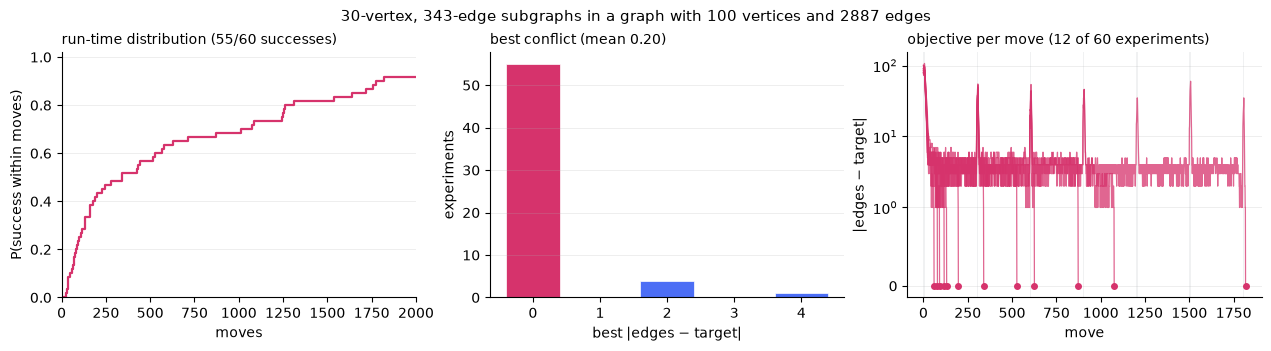

In [5]:
viz.plot_search_summary(r);

The **run-time distribution** (left) is the probability of success within a given number of moves: still rising at the budget means more moves would help. The traces (right) show the bursts of random moves every `div_freq` moves.

At this density the target is barely attainable: every success found the *same* vertex set.

In [6]:
len(r.solutions()), [len(ss.search(g, 30, m, experiments=60, max_moves=2000, div_freq=300, div_dur=8, seed=5).solutions()) for m in (330, 340)]

(1, [60, 33])

## Graph structure

Degree distribution against an Erdős–Rényi graph of the same density, the Laplacian spectrum (λ₁ > 0 means connected), and the adjacency matrix with the found subgraph moved to the top-left block.

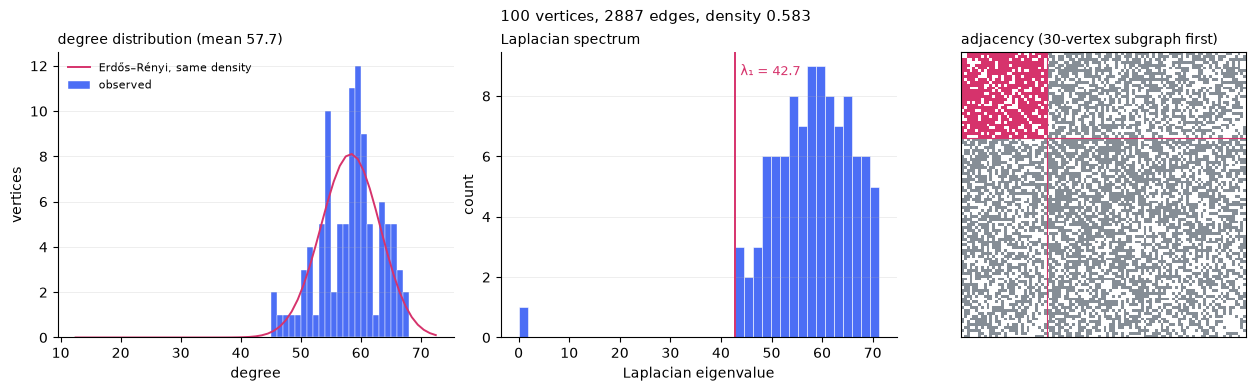

In [7]:
viz.plot_graph_summary(g, highlight=r.best.vertices);

`ggen`'s "power" model is not heavy-tailed, which the comparison makes plain:

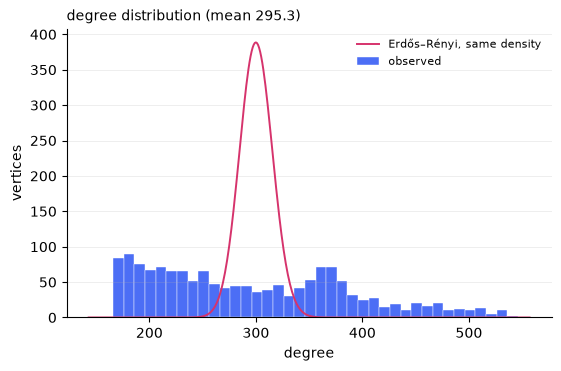

In [8]:
viz.plot_degree_distribution(ss.generate("power", 1500, 0.2, seed=52));

## Interactive view

A self-contained page: drag to pan, scroll to zoom, hover or click vertices, and pick a solution to highlight. `viz.save_html` writes the same page to a file.

In [9]:
viz.show(ss.search(g, 30, 330, experiments=8, seed=2), max_conflict=0)

## Tuning

`ss.sweep` reruns a search across values of one parameter.

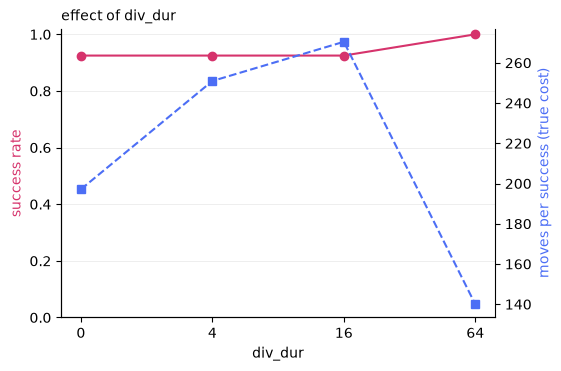

In [10]:
sweep = ss.sweep(g, 30, 340, "div_dur", [0, 4, 16, 64], experiments=40, max_moves=1500, div_freq=300)
viz.plot_sweep(sweep, parameter="div_dur");

## Weighted graphs

USRA's `wggen` and `wsub_search` work with integer edge weights; the target is then a total weight. Here, 15 vertices whose edges weigh 180 in total, in a graph with a mean weight of 0.65 per vertex pair.

In [11]:
w = ss.generate_weighted(200, 0.65, seed=1, rng="legacy")  # exactly wggen's `200 65 1`
rw = ss.search(w, 15, 180, experiments=40, max_moves=3000, div_freq=300, div_dur=10)
rw

target,"15 vertices, total weight 180"
experiments,40 × ≤3000 moves
successes,40 (100%)
relative cost,163.4 moves
true cost,163.4 moves
average conflict,0.000
rng / seed,xoshiro / 1


## Formats and other libraries

In [12]:
import tempfile, pathlib
from subsearch import convert

path = pathlib.Path(tempfile.mkdtemp()) / "g.g6"
g.write(path)
assert ss.read(path) == g
G = convert.to_networkx(g)
A = convert.to_scipy(g)
print(G, "|", repr(A))
print("formats:", ss.formats())

Graph with 100 nodes and 2887 edges | <Compressed Sparse Row sparse array of dtype 'int8'
	with 5774 stored elements and shape (100, 100)>
formats: {'lists': True, 'edgelist': True, 'graph6': True, 'sparse6': True, 'mtx': True, 'dot': False, 'graphml': False, 'wlists': True}


## The original interfaces

`ss.legacy` takes exactly what `sub_search` and `ggen` read on stdin and returns what they printed.

In [13]:
print(ss.legacy.ggen("2 10 0 500 42 0 0 0"))

2 10 0 500 42  0 0  0
 1 5 7 8-1
 4 7-1
 4 7-1
 6 8-1
 5 9-1
 8 9-1
 8 9-1
 9-1
 9-1
-1

V = 10, E = 18

2   : 2    3   : 2    4   : 4    5   : 2    

